### Célula 01 · Importações

In [56]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### Carregar os dados

In [57]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "estacoes"   # ex.: "livros"
NOME_TABELA_FATO = "leituras"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
estacoes -> 10050 linhas
leituras -> 62000 linhas


### Célula 03 · Conhecendo a tabela dimensão

In [58]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10050 linhas e 7 colunas (variáveis)


,estacao_id,nome_estacao,cidade,pais,latitude,longitude,altitude_m
0,1,EST-00001,Faro,Portugal,38.1875,-7.0071,210
1,2,EST-00002,Cardoso da Prata,Brasil,-6.2094,-61.1375,1078
2,3,EST-00003,Sapporo,Japão,31.9776,134.9049,2461
3,4,EST-00004,Tóquio,Japão,41.2972,138.4621,325
4,5,EST-00005,Vieira do Galho,Brasil,-30.6834,-42.3874,1357


### Célula 04 · Conhecendo a tabela fato

In [59]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 62000 linhas e 9 colunas (variáveis)


,leitura_id,estacao_id,data_hora,condicao_tempo,temperatura_c,umidade_pct,precipitacao_mm,velocidade_vento_kmh,pressao_hpa
0,1,1,2025-01-01 00:02:35,ensolarado,1.6,22.4,0.0,8.7,986.8
1,2,2,2025-01-01 00:18:50,nublado,16.3,60.1,0.0,2.1,898.4
2,3,3,2025-01-01 00:28:49,ensolarado,-12.9,50.4,0.0,9.3,761.4
3,4,4,2025-01-01 01:06:05,ensolarado,0.1,50.0,0.0,3.3,982.5
4,5,5,2025-01-01 01:57:28,ensolarado,8.9,37.9,0.0,6.0,882.2


### Tipos das colunas

### Célula 05 · Tipos das colunas

In [60]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62000 entries, 0 to 61999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   leitura_id            62000 non-null  int64  
 1   estacao_id            62000 non-null  int64  
 2   data_hora             62000 non-null  object 
 3   condicao_tempo        62000 non-null  object 
 4   temperatura_c         62000 non-null  float64
 5   umidade_pct           62000 non-null  float64
 6   precipitacao_mm       62000 non-null  float64
 7   velocidade_vento_kmh  62000 non-null  float64
 8   pressao_hpa           62000 non-null  float64
dtypes: float64(5), int64(2), object(2)
memory usage: 4.3+ MB


### Célula 06 · Valores ausentes

In [61]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
leitura_id              0
estacao_id              0
data_hora               0
condicao_tempo          0
temperatura_c           0
umidade_pct             0
precipitacao_mm         0
velocidade_vento_kmh    0
pressao_hpa             0
dtype: int64


### Célula 07 · Linhas duplicadas

In [62]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### Célula 08 · Chave estrangeira

In [63]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "estacao_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "estacao_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


### Leitura da conferência

**Leitura da conferência**

1. **Tamanho da tabela fato e se há linhas duplicadas**

- **R:** A tabela fato (leituras.csv) possui 62.000 linhas e 9 colunas, e não há nenhuma linha duplicada (0 registros repetidos).

2. **Se a chave estrangeira bate com a dimensão**

- **R:** A chave estrangeira (estacao_id) bate com a tabela dimensão (estacoes.csv), retornando True para todos os registros.

3. **Se a coluna de análise tem valores ausentes**

- **R:** Não, a coluna de análise velocidade_vento_kmh não possui valores ausentes.

4. **Se há valores ausentes em outras colunas e por que estão vazios: erro ou não**

- **R:** Não há valores ausentes em nenhuma outra coluna da tabela fato


### Célula 09 · Checar a coluna numérica

In [64]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "velocidade_vento_kmh"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 62000 | ausentes: 0


### Célula 10 · Medidas estatísticas

In [65]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,11.94
Mediana,9.70
Moda,6.00
Desvio padrão,9.25
Variância,85.57
Mínimo,0.00
Máximo,157.40
Amplitude,157.40


Média - mediana: 2.24


### Passo 6 — Escrever as frases de insight

##### Generated-by: AI Gemini
##### AI-Generated-Date: 2026-11-16
##### SPDX-SnippetCopyrightText: AI-Assisted Code
##### SPDX-License-Identifier: MIT

1. **A média de (coluna) é (valor)**. **(O que a média significa para o seu tema.)**

- **R:** A média de velocidade_vento_kmh é 11,94 km/h. O vento médio da rede é fraco, mas às vezes chega por até 157,40 km/h.

2. **A mediana de (coluna) é (valor)**. (**O que a mediana mostra e como ela se compara à média.)**

- **R:** A mediana de velocidade_vento_kmh é 9,70 km/h. Metade das medições tem vento abaixo desse valor, ou seja, ventos fortes são exceções.

3. **O desvio padrão de (coluna) é (valor)**. **(O que a variação mostra.)**

- **R:** O desvio padrão de velocidade_vento_kmh é 9,25 km/h. A alta variação em relação à média confirma que o vento fica forte em raros momentos.

4. **Decisão final:** (**escreva uma frase com a decisão que as três medidas apoiam.)**

- **R:** Emitir alertas de ventos fortes apenas durante previsões de tempestade. Porque a maioria das medições tem vento fraco (mediana de 9,70 km/h), mas ocorrem picos isolados de até 157,40 km/h que elevam a média para 11,94 km/h e o desvio padrão para 9,25 km/h



### Célula 11 · Juntar a fato com a dimensão

In [66]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 62000 | depois da junção: 62000


### Célula 12 · Comparar grupos por uma coluna da fato

In [67]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "condicao_tempo"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
condicao_tempo,,,,
tempestade,1848,27.88,23.4,20.17
chuvoso,5604,14.29,12.0,10.20
nublado,31020,12.02,10.1,8.48
ensolarado,23528,10.02,8.5,7.01


### Leitura da comparação

##### Generated-by: AI Gemini
##### AI-Generated-Date: 2026-11-16
##### SPDX-SnippetCopyrightText: AI-Assisted Code
##### SPDX-License-Identifier: MIT

**Leitura por (condicao_tempo)**

1. **Grupo com a maior média e se a mediana confirma**

- **R:** O grupo tempestade possui a maior média (27,88 km/h) e a mediana (23,40 km/h) confirma que os ventos são muito mais fortes nessa condição, ficando mais que o dobro acima dos demais grupos.

2. **Grupo com o maior desvio padrão: valores mais espalhados**

- **R:** O grupo tempestade também apresenta o maior desvio padrão (20,17 km/h), indicando valores muito mais espalhados e rajadas fortes durante esses eventos.

3. **Se os grupos têm médias parecidas, o que isso diz sobre a categoria**

- **R:**  Os grupos chuvoso, nublado e ensolarado têm médias parecidas e baixas (entre 10,02 km/h e 14,29 km/h), o que mostra que o vento forte não é comum no dia a dia da rede e se concentra nos momentos de tempestade.

### Célula 13 · Comparar grupos por uma coluna da dimensão

In [68]:
COLUNA_GRUPO = "pais"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
pais,,,,
França,3932,12.15,9.9,9.43
Portugal,3218,12.13,9.8,9.62
Argentina,3742,11.98,9.7,9.35
Brasil,18476,11.97,9.8,9.12
Austrália,3175,11.95,9.6,9.38
Estados Unidos,6064,11.93,9.6,9.32
África do Sul,2555,11.92,9.6,9.60
México,3059,11.91,9.9,8.97
Índia,2405,11.89,9.6,9.14


### Célula 14 · Regra do IQR

In [69]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -9.95 a 31.25
Outliers: 2300 de 62000 valores
Maiores valores: [157.4, 127.6, 123.4, 122.8, 121.4]
Menores valores: [0.0, 0.0, 0.0, 0.0, 0.0]


### Célula 15 · Medidas com e sem os candidatos a outlier

In [70]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,11.94,10.79
Mediana,9.70,9.40
Desvio padrão,9.25,6.87


### Leitura e decisão registrada

##### Generated-by: AI Gemini
##### AI-Generated-Date: 2026-11-16
##### SPDX-SnippetCopyrightText: AI-Assisted Code
##### SPDX-License-Identifier: MIT

**Leitura e decisão registrada**

1.   **(Quantos valores a regra do IQR marcou, a partir de que valor, e como as medidas mudam sem eles):**

- **R:** A regra do IQR marcou 2.300 valores (de 62.000) como outliers, todos acima de 31,25 km/h; sem eles, a média cai de 11,94 para 10,79 km/h, o desvio padrão cai de 9,25 para 6,87 km/h e a mediana vai de 9,70 para 9,40 km/h.

2.   **Decisão:** **(manter, tratar ou excluir) e o porquê:**

- **R:** Manter os registros, pois ventos de até 157,40 km/h são fenômenos reais de tempestades e são o foco da análise.

3.   **Valores ausentes:** **(o que foi feito com eles e por quê):**

- **R:** Nenhuma ação foi necessária, pois a tabela tem 0 valores vazios.




### Célula 16 · Assimetria (skew)

In [71]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.25


### Célula 17 · Percentis

In [72]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     3.1
0.25     5.5
0.50     9.7
0.75    15.8
0.90    23.3
Name: velocidade_vento_kmh, dtype: float64


### Célula 18 · Quantidade de valores por faixa

In [73]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
velocidade_vento_kmh,
"(-0.157, 31.48]",59758
"(31.48, 62.96]",2088
"(62.96, 94.44]",135
"(94.44, 125.92]",17
"(125.92, 157.4]",2


### Leitura da distribuição

##### Generated-by: AI Gemini
##### AI-Generated-Date: 2026-11-16
##### SPDX-SnippetCopyrightText: AI-Assisted Code
##### SPDX-License-Identifier: MIT

**Leitura da distribuição**

1. **Valor da assimetria e o que ele indica sobre a cauda**

**R:** A assimetria é 2,25 (positiva), mostrando uma cauda para valores altos puxada por poucos picos extremos.

2. **Percentis: até que valor ficam 75% e 90% dos registros**

**R:** Pelos percentis, 75% dos registros ficam até 15,8 km/h e 90% ficam até 23,3 km/h.

3. **Quantos registros estão na primeira faixa e quantos ficam nas faixas mais altas**

**R:** Na primeira faixa (até 31,48 km/h) estão 59.758 registros, enquanto apenas 2.242 ficam nas faixas mais altas.

4. **Em palavras: a maioria dos valores fica entre X e Y, e poucos passam de Z**

**R:** A maioria dos valores fica entre 0,0 km/h e 23,3 km/h, e poucos passam de 31,48 km/h.

### Passo 10 — Redigir a recomendação de decisão

## Recomendação

**Pergunta de negócio:** Os ventos fortes são comuns em toda a rede ou se concentram apenas no momento de tempestade?

##### Generated-by: AI Gemini
##### AI-Generated-Date: 2026-11-16
##### SPDX-SnippetCopyrightText: AI-Assisted Code
##### SPDX-License-Identifier: MIT

**Evidência 1: (medida + valor + o que significa)**

R: A mediana é de 9,70 km/h e a média é de 11,94 km/h. Isso mostra que quase sempre o vento é fraco e os ventos fortes são raros.

**Evidência 2: (medida + valor + o que significa)**

R: Nas tempestades, a média sobe para 27,88 km/h, enquanto nos outros climas fica abaixo de 14,29 km/h e todos os países têm médias iguais (cerca de 11,8 km/h).

**Recomendação em uma frase:**

R: Só devemos emitir alerta de vento forte quando houver previsão de tempestade.

**Limites da análise: (os dados são fictícios; o que foi feito com outliers e ausentes, conforme o Passo 8)**

### Célula 19 · Histograma

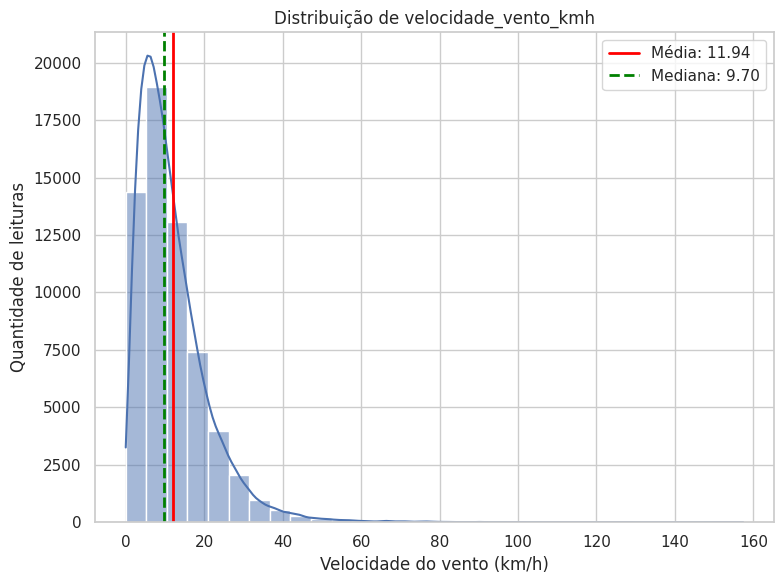

In [74]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Velocidade do vento (km/h)")
plt.ylabel("Quantidade de leituras")
plt.legend()
plt.tight_layout()
plt.show()

### Célula 20 · Boxplot

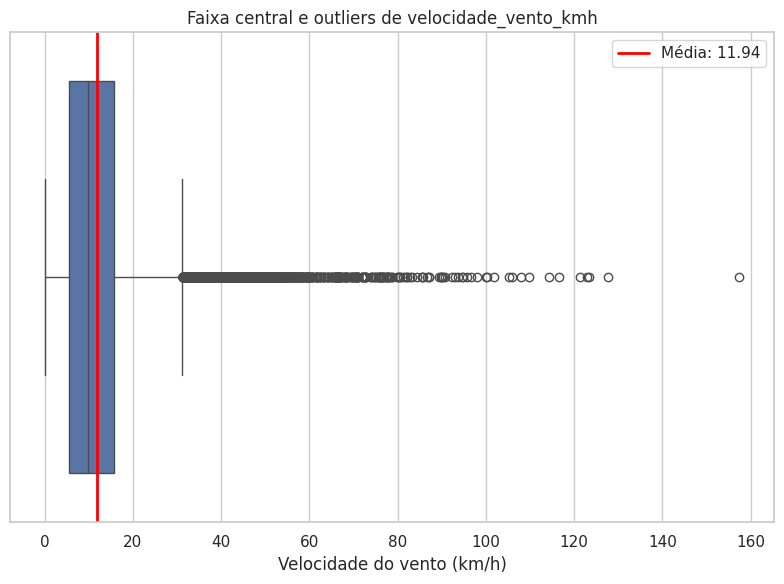

In [75]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Velocidade do vento (km/h)")
plt.legend()
plt.tight_layout()
plt.show()